# 📘 Explained copy — 06 Portfolio optimisation (Module 6)

Study copy of `notebooks/06_portfolio.ipynb`. Original cells unchanged (with outputs); above each is an **Explanation**:
*what it does · why this method · input → output · how to read the output vs alternatives*.

**Story for the report.** Turn notebook 05's weak ML forecasts into portfolios and compare five strategies on the same
37–38 out-of-sample months with identical rules (monthly, long-only, 30% cap, 10 bps cost): **equal-weight, classic
Markowitz max-Sharpe (sample means/cov), minimum variance (Ledoit-Wolf), ML mean-variance (Ridge views + LW cov),
ML tilt**. Classic Markowitz fails (Sharpe 0.15 — "error maximisation"); ML tilt has the best Sharpe (1.43) but is
**not significant** vs equal-weight (p = 0.16). A **simplicity rule** (need +0.10 Sharpe *and* p < 0.10) keeps
**equal-weight** (Sharpe 1.30). Crisis stress (ρ = 0.6, vol × 2) raises 1-month 99% VaR from ~5% to **~30%**.

**Key numbers:** EW 16.1% / 6.3% vol / Sharpe 1.30 / MDD −2.4% · Markowitz 0.15 · ML MV 1.38 (turnover 103%) ·
ML tilt 1.43 · crisis VaR 30.2% · equity line return for nb 10 = 13.3% (long-run anchor).

> ### 📘 Explanation — cell 0
> **What it is.** Business question (how to turn forecasts into a portfolio; does ML beat simpler approaches after costs
> and risk?), the 5 strategies table and the common rules.
>
> **Why these five.** The brief asks for equal-weight, traditional Markowitz and an ML portfolio. Minimum variance
> (no return estimates) and ML tilt (gentle use of forecasts) are added because they isolate *where* value or error comes
> from: return estimates vs risk estimates vs ML views. Identical dates, costs and constraints make the comparison fair.

# 06. Portfolio optimisation (Module 6)

**Business question.** Notebook 05 produced ML return forecasts. How should NovaFin turn forecasts into an actual
equity portfolio, and does the ML portfolio beat simpler approaches **after costs and risk**?

**Chain.** ML forecasts (notebook 05) + historical risk estimates → portfolio weights for each strategy
→ monthly out-of-sample backtest after costs → return, risk, VaR, drawdown → stress test → the equity line
for notebook 10 (expected return, risk and capital at risk).

**Strategies compared (brief: equal-weight, traditional Markowitz, ML-predicted-return portfolio).**

| # | Strategy | Expected returns used | Risk model |
|---|---|---|---|
| 1 | Equal-weight | none (1/15 each) | none |
| 2 | Markowitz max-Sharpe (traditional) | trailing 1-year average returns | sample covariance |
| 3 | Minimum variance | none | Ledoit-Wolf shrunk covariance |
| 4 | ML mean-variance | Ridge forecasts from notebook 05 | Ledoit-Wolf shrunk covariance |
| 5 | ML tilt | equal-weight, tilted towards the ML favourites | none |

**Common rules (keep the comparison fair).** Same 38 out-of-sample months as notebook 05 (Jul 2023 – Aug 2026),
monthly rebalance at month-end, long-only, max 30% in one stock, fully invested, 10 bps cost per unit traded.
Only data up to each rebalance date is used to set weights.

> ### 📘 Explanation — cell 1
> **What it does.** Loads helpers and sets output folders for Module 6.

In [1]:
import sys; sys.path.insert(0, '../src')   # make the shared helper module importable
from novafin import *                       # shared assumptions, loaders, metrics, plot style
RES, FIG = use_module('06')                 # this module's output folders (results/ and figures/)

NovaFin helpers loaded. Root: C:\Users\pravi\PG IITB\Machine Learning in Finance\capstone project solution\novafin_capstone
Outputs -> results/Module_06_Portfolio_Optimisation/ and figures/Module_06_Portfolio_Optimisation/


> ### 📘 Explanation — cell 2
> **What it does.** Imports `scipy.optimize.minimize` (SLSQP solver), **LedoitWolf** shrinkage covariance, scipy.stats.
>
> **Why Ledoit-Wolf.** The sample covariance of 15 stocks from 252 days is noisy; LW shrinks it toward a structured target,
> giving more stable (better-conditioned) matrices → more stable weights. Taught in the course.

In [2]:
from scipy.optimize import minimize                 # numerical optimiser for the Markowitz problems
from sklearn.covariance import LedoitWolf           # shrinkage covariance (more stable than the sample one)
from scipy import stats                             # t-tests and the normal quantile for VaR
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)

> ### 📘 Explanation — cell 3
> **What it does.** Risk-free 7%, cost 10 bps, **30% cap per stock**, 252-day estimation window, **z₉₉ = 2.326** for 99% VaR.
>
> **Why a cap.** Unconstrained Markowitz tends to put everything into a few stocks; a cap is the standard concentration limit.

In [3]:
RF = ASSUMPTIONS['RISK_FREE']        # 7% a year
TC = 0.0010                          # 10 bps per unit of value traded (same as notebook 05)
CAP = 0.30                           # max weight in one stock (concentration limit)
WINDOW = 252                         # one year of daily data to estimate means and covariances
Z99 = stats.norm.ppf(ASSUMPTIONS['VAR_CONFIDENCE'])   # 2.326 for 99% VaR
print('risk-free', RF, '| cost', TC, '| cap', CAP, '| window', WINDOW, '| z99', round(Z99, 3))

risk-free 0.07 | cost 0.001 | cap 0.3 | window 252 | z99 2.326


> ### 📘 Explanation — cell 4
> **What it does.** Loads daily returns (pivot: dates × 15 tickers) and notebook 05's predictions (only months with known outcomes).
>
> **Output.** daily (1,457, 15); **37 rebalance dates**, 2023-07-31 → 2026-07-31.

In [4]:
mkt = load('market', parse_dates=['Date'])                                    # daily prices
daily = mkt.pivot(index='Date', columns='Ticker', values='Return').sort_index()   # dates x 15 tickers
pred = pd.read_csv(result_file('05', 'equity_predictions.csv'), parse_dates=['Date'])   # ML forecasts from notebook 05
pred = pred.dropna(subset=['Fwd_Ret'])                                        # keep months whose outcome is known
dates = sorted(pred.Date.unique())                                            # 38 rebalance dates
TICKERS = list(daily.columns)
print('daily returns', daily.shape, '| rebalance dates', len(dates), pd.Timestamp(dates[0]).date(), 'to', pd.Timestamp(dates[-1]).date())

daily returns (1457, 15) | rebalance dates 37 2023-07-31 to 2026-07-31


> ### 📘 Explanation — cell 5
> **Section header** – each building-block function returns 15 weights ≥ 0, summing to 1, each ≤ 30%.

## 1. Portfolio building blocks
Each function below returns a weight vector (15 numbers, ≥ 0, summing to 1, each ≤ 30%).

> ### 📘 Explanation — cell 6
> **What it does.**
> - `equal_weight()` → 1/15 each.
> - `_solve()` → SLSQP minimisation with Σw = 1 and 0 ≤ w ≤ 30%.
> - `max_sharpe(mu, cov)` → maximises (wᵀμ − r_f)/√(wᵀΣw) = **tangency portfolio**.
> - `min_variance(cov)` → minimises wᵀΣw (**GMVP**, ignores returns).
> - `ml_tilt(score)` → 1/N scaled by percentile rank of the forecast: weights between 0.5/N and 1.5/N.
>
> **Why SLSQP.** It handles the equality (fully invested) and bound (long-only, cap) constraints directly.
> **Why a tilt.** With a weak signal, small deviations from 1/N capture some edge without losing diversification.

In [5]:
def equal_weight(mu=None, cov=None):
    """Strategy 1: 1/N in every stock."""
    return np.full(len(TICKERS), 1 / len(TICKERS))

def _solve(objective, n):
    """Minimise `objective(w)` subject to long-only, cap and fully-invested constraints."""
    cons = [{'type': 'eq', 'fun': lambda w: w.sum() - 1}]                 # weights add up to 100%
    bounds = [(0, CAP)] * n                                                # 0% to 30% per stock
    res = minimize(objective, np.full(n, 1 / n), bounds=bounds, constraints=cons, method='SLSQP')
    w = np.clip(res.x, 0, None)                                            # tidy tiny negatives from the solver
    return w / w.sum()

def max_sharpe(mu, cov):
    """Strategies 2 and 4: maximise (expected return - risk-free) / volatility."""
    neg_sharpe = lambda w: -(w @ mu - RF) / np.sqrt(w @ cov @ w)           # minimise the negative Sharpe
    return _solve(neg_sharpe, len(mu))

def min_variance(mu, cov):
    """Strategy 3: lowest possible volatility, ignores expected returns entirely."""
    return _solve(lambda w: w @ cov @ w, len(cov))

def ml_tilt(score, strength=0.5):
    """Strategy 5: equal-weight, scaled up/down by the ML rank. strength 0.5 => weights from 0.5/N to 1.5/N."""
    r = pd.Series(score).rank(pct=True).values - 0.5          # -0.5 (worst forecast) .. +0.5 (best forecast)
    w = (1 + 2 * strength * r) / len(r)                       # tilt around 1/N
    return w / w.sum()

> ### 📘 Explanation — cell 7
> **What it does.** `estimates(t)` → annualised mean (×252) and covariance (×252) from the last 252 days **up to t**
> (only past data); covariance either sample or Ledoit-Wolf.

In [6]:
def estimates(t, shrink=True, window=WINDOW):
    """Annualised mean vector and covariance from the `window` trading days up to and including date t."""
    hist = daily.loc[:t].tail(window)                                    # only past data
    mu = hist.mean().values * 252                                        # annualised average return
    cov = (LedoitWolf().fit(hist.values).covariance_ if shrink else hist.cov().values) * 252   # annualised covariance
    return mu, cov

> ### 📘 Explanation — cell 8
> **Section header** – monthly walk-forward backtest.

## 2. Monthly walk-forward backtest

> ### 📘 Explanation — cell 9
> **What it does.** `backtest(strategy)`: at each month-end computes weights for the strategy; realised return = w·r(next month);
> **turnover** = Σ|w_new − w_drifted| (weights drift with prices between rebalances); net = gross − cost × turnover;
> records max weight and **effective N = 1/Σw²**.
>
> **ML mean-variance detail.** μ = cross-sectional average historical return + 12 × Ridge excess forecast (annualised
> relative view); covariance = LW.
>
> **Why drifted weights.** Realistic turnover: even equal-weight must trade a little each month to rebalance back to 1/N.

In [7]:
def backtest(strategy, tc=TC, cap=CAP, window=WINDOW):
    """Rebalance at each month-end with weights from `strategy`; return monthly net returns and diagnostics."""
    global CAP
    old_cap, CAP = CAP, cap                                                    # allow a cap sensitivity test
    rows, w_prev_drift, weights = [], None, {}
    try:
        for t in dates:
            month = pred[pred.Date == t].set_index('Ticker').reindex(TICKERS)    # this month's 15 stocks
            if strategy == 'Equal-weight':
                w = equal_weight()
            elif strategy == 'Markowitz max-Sharpe':
                mu, cov = estimates(t, shrink=False, window=window); w = max_sharpe(mu, cov)
            elif strategy == 'Minimum variance':
                mu, cov = estimates(t, window=window); w = min_variance(mu, cov)
            elif strategy == 'ML mean-variance':
                mu_hist, cov = estimates(t, window=window)
                mu = mu_hist.mean() + 12 * month.Pred_Ridge.values            # market average + ML relative view (annualised)
                w = max_sharpe(mu, cov)
            elif strategy == 'ML tilt':
                w = ml_tilt(month.Pred_Ridge.values)
            r = month.Fwd_Ret.values                                          # realised next-month returns
            turnover = 1.0 if w_prev_drift is None else np.abs(w - w_prev_drift).sum()   # value traded (first month: buy in)
            gross = float(w @ r)
            rows.append({'Date': t, 'gross': gross, 'net': gross - tc * turnover, 'turnover': turnover,
                         'max_weight': w.max(), 'effective_n': 1 / (w ** 2).sum()})
            weights[t] = w
            w_prev_drift = w * (1 + r) / (w * (1 + r)).sum()                  # weights drift with prices until next rebalance
    finally:
        CAP = old_cap
    return pd.DataFrame(rows).set_index('Date'), pd.DataFrame(weights, index=TICKERS).T

> ### 📘 Explanation — cell 10
> **What it does.** Runs all 5 strategies; quick check of average annual net return.
>
> **Output.** EW 15.2%, Markowitz 8.9%, MinVar 15.1%, ML MV 21.4%, ML tilt 17.1%.

In [8]:
STRATS = ['Equal-weight', 'Markowitz max-Sharpe', 'Minimum variance', 'ML mean-variance', 'ML tilt']
bt, W = {}, {}
for s in STRATS:
    bt[s], W[s] = backtest(s)                    # run every strategy on the same dates and costs
print({s: round(bt[s].net.mean() * 12, 4) for s in STRATS})   # quick check: average annual net return

{'Equal-weight': np.float64(0.1517), 'Markowitz max-Sharpe': np.float64(0.0886), 'Minimum variance': np.float64(0.1505), 'ML mean-variance': np.float64(0.2143), 'ML tilt': np.float64(0.1707)}


> ### 📘 Explanation — cell 11
> **Metrics.** Annual compound return, volatility, Sharpe, **Sortino** (downside vol only), **max drawdown**, **parametric 1-month VaR₉₉** = −(μ − 2.326σ), turnover, effective N.

## 3. Performance metrics
- **Annual return** (compound), **volatility**, **Sharpe** = (return − 7%) / volatility.
- **Sortino** uses only downside volatility. **Max drawdown** = worst peak-to-trough fall.
- **1-month VaR 99%** (parametric) = loss not exceeded in 99% of months: −(μ − 2.326 σ).
- **Turnover** = share of the portfolio traded per month; **effective N** = 1 / Σw² (15 = perfectly spread).

> ### 📘 Explanation — cell 12
> **What it does.** Computes the full metric set for every strategy.
>
> **Output.**
> | Strategy | Return | Vol | Sharpe | Sortino | MDD | VaR99 | Turnover | Eff. N |
> |---|---|---|---|---|---|---|---|---|
> | EW | 16.1% | 6.3% | 1.30 | 3.36 | −2.4% | 3.0% | 7% | 15.0 |
> | Markowitz | 8.4% | 12.3% | **0.15** | 0.23 | −13.3% | 7.6% | 37% | 6.4 |
> | Min var | 15.9% | 6.3% | 1.28 | 3.15 | −2.7% | 3.0% | 7% | 15.0 |
> | ML MV | **23.0%** | 10.5% | 1.38 | 2.81 | −5.5% | 5.3% | **103%** | 7.9 |
> | ML tilt | 18.2% | 7.0% | **1.43** | 3.39 | −3.0% | 3.3% | 31% | 13.9 |
>
> **How to read.** Markowitz concentrates (eff. N 6) and fails; min-var ≈ EW (stocks have similar vol and ~0 correlation,
> so the GMVP *is* nearly 1/N); ML strategies look better but at higher turnover.

In [9]:
def metrics(b):
    r = b.net                                                              # monthly net returns
    ann_ret = (1 + r).prod() ** (12 / len(r)) - 1
    ann_vol = r.std() * np.sqrt(12)
    downside = r[r < 0].std() * np.sqrt(12)
    wealth = (1 + r).cumprod(); mdd = (wealth / wealth.cummax() - 1).min()
    return {'Ann. return': ann_ret, 'Ann. vol': ann_vol,
            'Sharpe': (r.mean() * 12 - RF) / ann_vol,
            'Sortino': (r.mean() * 12 - RF) / downside if downside > 0 else np.nan,
            'Max drawdown': mdd, 'VaR 99% 1-month': -(r.mean() - Z99 * r.std()),
            'Avg turnover': b.turnover.iloc[1:].mean(), 'Avg max weight': b.max_weight.mean(),
            'Effective N': b.effective_n.mean(), 'Cost drag / yr': (b.gross - b.net).iloc[1:].mean() * 12}

perf = pd.DataFrame({s: metrics(bt[s]) for s in STRATS}).T
perf.round(4)

,Ann. return,Ann. vol,Sharpe,Sortino,Max drawdown,VaR 99% 1-month,Avg turnover,Avg max weight,Effective N,Cost drag / yr
Equal-weight,0.1605,0.0628,1.3007,3.3567,-0.0244,0.0295,0.0663,0.0667,15.0000,0.0008
Markowitz max-Sharpe,0.0842,0.1234,0.1504,0.2285,-0.1334,0.0755,0.3740,0.2406,6.3935,0.0045
Minimum variance,0.1591,0.0631,1.2763,3.1487,-0.0268,0.0298,0.0679,0.0697,14.9843,0.0008
ML mean-variance,0.2303,0.1048,1.3767,2.8063,-0.0554,0.0525,1.0290,0.2030,7.9418,0.0123
ML tilt,0.1820,0.0702,1.4338,3.3915,-0.0297,0.0329,0.3119,0.0968,13.9186,0.0037


> ### 📘 Explanation — cell 13
> **Header** – comparison vs equal-weight.

### Strategy comparison: what does each choice gain over equal-weight?

> ### 📘 Explanation — cell 14
> **What it does.** `compare_models` ranking by Sharpe with EW as baseline.
>
> **Output.** ML tilt +0.133, ML MV +0.076, MinVar −0.024, Markowitz **−1.15**.

In [10]:
cmp = compare_models(perf, 'Sharpe', chosen=None, baseline='Equal-weight',
                     extra=['Ann. return', 'Ann. vol', 'Max drawdown', 'VaR 99% 1-month', 'Avg turnover', 'Effective N'])
cmp.round(4)

,Rank,Sharpe,Ann. return,Ann. vol,Max drawdown,VaR 99% 1-month,Avg turnover,Effective N,Gain vs baseline,Gap to best,Chosen
ML tilt,1,1.4338,0.1820,0.0702,-0.0297,0.0329,0.3119,13.9186,0.1331,0.0000,
ML mean-variance,2,1.3767,0.2303,0.1048,-0.0554,0.0525,1.0290,7.9418,0.0760,0.0571,
Equal-weight,3,1.3007,0.1605,0.0628,-0.0244,0.0295,0.0663,15.0000,0.0000,0.1331,
Minimum variance,4,1.2763,0.1591,0.0631,-0.0268,0.0298,0.0679,14.9843,-0.0243,0.1575,
Markowitz max-Sharpe,5,0.1504,0.0842,0.1234,-0.1334,0.0755,0.3740,6.3935,-1.1503,1.2834,


> ### 📘 Explanation — cell 15
> **What it does.** Paired one-sample t-test on monthly net return differences vs EW; also **tracking error** (std of the
> difference × √12).
>
> **Output.** ML MV +6.3%/yr, t = 1.60, **p = 0.12**, TE 6.9%; ML tilt +1.9%/yr, t = 1.45, **p = 0.16**, TE 2.3%;
> Markowitz −6.3%/yr, p = 0.27.
>
> **How to read.** No strategy differs significantly from EW at conventional levels. ML tilt has low tracking error, i.e. it
> stays close to the benchmark.

In [11]:
# Statistical check: is any strategy's monthly return significantly different from equal-weight?
sig = {}
for s in STRATS[1:]:
    d = bt[s].net - bt['Equal-weight'].net                                     # monthly difference
    t_res = stats.ttest_1samp(d, 0)                                            # H0: no difference on average
    sig[s] = {'mean monthly diff': d.mean(), 'ann. diff': d.mean() * 12, 't-stat': t_res.statistic, 'p-value': t_res.pvalue,
              'tracking error': d.std() * np.sqrt(12)}
pd.DataFrame(sig).T.round(4)

,mean monthly diff,ann. diff,t-stat,p-value,tracking error
Markowitz max-Sharpe,-0.0053,-0.0631,-1.1309,0.2656,0.0980
Minimum variance,-0.0001,-0.0012,-0.7793,0.4409,0.0026
ML mean-variance,0.0052,0.0626,1.5991,0.1185,0.0687
ML tilt,0.0016,0.0190,1.4484,0.1562,0.0231


> ### 📘 Explanation — cell 16
> **What it does.** Selection rule (simplest first): switch from EW only if Sharpe improves by > 0.10 **and** p < 0.10.
>
> **Output.** **Chosen: Equal-weight.**
>
> **Why this rule.** With 37 months, Sharpe differences of a few tenths are noise; requiring both economic (+0.10) and
> statistical (p < 0.10) evidence prevents adopting a strategy that only looked good by luck (overfitting the backtest).

In [12]:
# Selection rule: prefer the simplest strategy unless a more complex one improves Sharpe by more than 0.10
# AND beats it with p < 0.10. Order = simplest first.
simplicity = ['Equal-weight', 'ML tilt', 'Minimum variance', 'Markowitz max-Sharpe', 'ML mean-variance']
chosen = 'Equal-weight'
for s in simplicity[1:]:
    better = perf.loc[s, 'Sharpe'] - perf.loc[chosen, 'Sharpe'] > 0.10
    significant = sig[s]['p-value'] < 0.10
    if better and significant:
        chosen = s
print('Chosen strategy for the equity sleeve:', chosen)

Chosen strategy for the equity sleeve: Equal-weight


> ### 📘 Explanation — cell 17
> **What it does.** Growth of ₹1 after costs, risk–return scatter, and Markowitz weights over time (area chart). Saves `portfolio_backtest.png`. The weight chart shows Markowitz jumping between a few stocks — visual proof of estimation error.

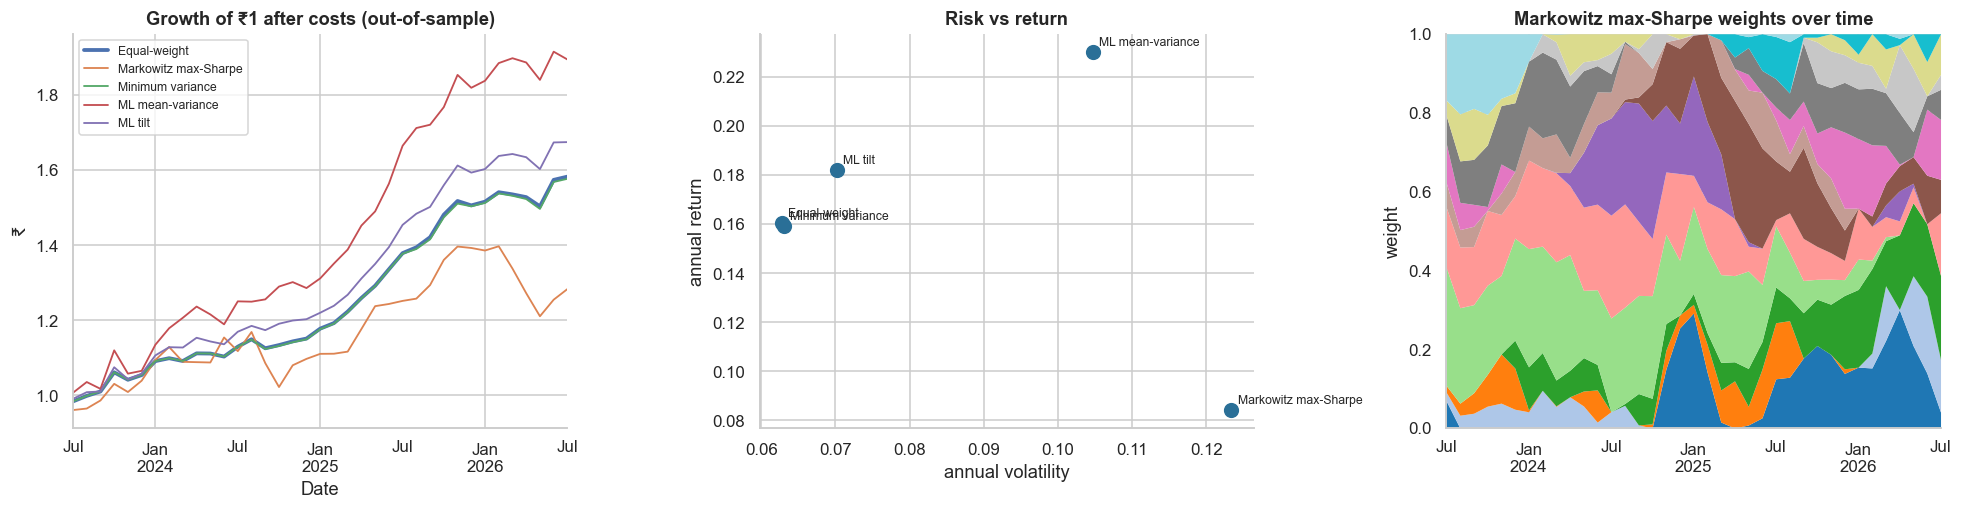

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for s in STRATS:
    (1 + bt[s].net).cumprod().plot(ax=ax[0], label=s, lw=2.5 if s == chosen else 1.2)    # growth of ₹1
ax[0].set(title='Growth of ₹1 after costs (out-of-sample)', ylabel='₹'); ax[0].legend(fontsize=8)
ax[1].scatter(perf['Ann. vol'], perf['Ann. return'], s=80, c='#2a6f97')                   # risk vs return
for s in STRATS:
    ax[1].annotate(s, (perf.loc[s, 'Ann. vol'], perf.loc[s, 'Ann. return']), fontsize=8, xytext=(4, 4), textcoords='offset points')
ax[1].set(title='Risk vs return', xlabel='annual volatility', ylabel='annual return')
W['Markowitz max-Sharpe'].plot.area(ax=ax[2], legend=False, lw=0, cmap='tab20')          # how weights move
ax[2].set(title='Markowitz max-Sharpe weights over time', ylabel='weight'); ax[2].set_ylim(0, 1)
plt.tight_layout(); savefig('portfolio_backtest'); plt.show()

> ### 📘 Explanation — cell 18
> **Interpretation.** Markowitz = 'error maximisation' (optimiser amplifies noisy mean estimates); min-var ≈ EW; ML MV amplifies weak forecasts; ML tilt uses them gently. Nothing beats EW significantly → keep the simplest.

**Reading the results.**
- The **traditional Markowitz** portfolio chases last year's winners: its weights jump around (see the right panel),
  it concentrates in a few stocks, trades heavily, and the past winners do not keep winning. This is the textbook
  "error maximisation" problem of mean-variance with estimated means.
- **Minimum variance** ignores return forecasts and only uses risk. Because the 15 stocks have similar volatility and
  almost no correlation, it ends up close to equal-weight.
- **ML mean-variance** feeds weak forecasts (IC ≈ 0.06, not significant) into an optimiser that amplifies them.
  **ML tilt** uses the same forecasts gently, so it stays close to equal-weight.
- No strategy beats equal-weight significantly, so the selection rule keeps the simplest one.

> ### 📘 Explanation — cell 19
> **Sensitivity question.** Does the conclusion change with costs, the cap, or the estimation window?

## 4. Sensitivity analysis
Does the conclusion change with costs, the concentration cap or the estimation window?

> ### 📘 Explanation — cell 20
> **What it does.** Re-runs backtests with costs 0/10/30 bps, caps 20%/50%, windows 126/504 days.
>
> **Output (Sharpe).** At 30 bps ML MV falls to **1.148 < EW 1.260**; Markowitz stays poor (−0.17 to 0.32) under every
> window/cap; ML MV with 20% cap 1.23.
>
> **How to read.** ML MV's edge is cost-fragile (103% turnover); Markowitz's failure is robust → conclusion unchanged.

In [14]:
sens_rows = {}
for tc in [0.0, 0.0010, 0.0030]:                                              # 0, 10, 30 bps
    for s in ['Equal-weight', 'Markowitz max-Sharpe', 'ML mean-variance']:
        sens_rows[(f'cost {tc * 1e4:.0f} bps', s)] = metrics(backtest(s, tc=tc)[0])['Sharpe']
for cap in [0.20, 0.50]:
    for s in ['Markowitz max-Sharpe', 'ML mean-variance']:
        sens_rows[(f'cap {cap:.0%}', s)] = metrics(backtest(s, cap=cap)[0])['Sharpe']
for win in [126, 504]:
    sens_rows[(f'window {win}d', 'Markowitz max-Sharpe')] = metrics(backtest('Markowitz max-Sharpe', window=win)[0])['Sharpe']
sens = pd.Series(sens_rows, name='Sharpe').unstack()
sens.round(3)

,Equal-weight,ML mean-variance,Markowitz max-Sharpe
cap 20%,NaN,1.227,0.324
cap 50%,NaN,1.469,0.117
cost 0 bps,1.321,1.490,0.189
cost 10 bps,1.301,1.377,0.150
cost 30 bps,1.260,1.148,0.074
window 126d,NaN,NaN,-0.169
window 504d,NaN,NaN,0.325


> ### 📘 Explanation — cell 21
> **Crisis stress design.** Correlations jump and volatility rises in crises: rebuild covariance with all ρ = 0.6 and vol × 2; compute 1-month 99% VaR on latest weights, plus a −25% beta-weighted market shock.

## 5. Stress test: what if a crisis hits?
Diversification works here because the stocks are almost uncorrelated. In a crisis, correlations jump and
volatility rises. We rebuild the covariance with **all correlations = 0.6 and volatility × 2** and compute the
1-month 99% VaR for the latest weights of each strategy, plus an instant **−25% market shock** (beta-weighted).

> ### 📘 Explanation — cell 22
> **What it does.** Normal 1-month covariance (daily × 21) vs crisis covariance = (2σᵢ)(2σⱼ)·0.6·21; VaR = 2.326 × √(wᵀΣw);
> beta to EW market; shock loss = −25% × portfolio beta; worst backtest month.
>
> **Output.** EW VaR **5.3% normal → 30.2% crisis**; all strategies ≈ 30–31% in crisis; −25% shock costs ≈ 25–26% for all.
>
> **How to read.** Diversification evaporates when correlations rise — long-only equity loses roughly the market's fall.
> This is why notebook 10 sizes equity capital on the **crisis** VaR and notebook 08 looks at put hedges.

In [15]:
t_last = dates[-1]                                                       # latest rebalance date
hist = daily.loc[:t_last].tail(WINDOW)
vol_d = hist.std().values                                                # daily vol per stock
corr_crisis = np.full((15, 15), 0.6); np.fill_diagonal(corr_crisis, 1)   # crisis correlation matrix
cov_normal = hist.cov().values * 21                                      # 1-month covariance, normal times
cov_crisis = np.outer(2 * vol_d, 2 * vol_d) * corr_crisis * 21           # 1-month covariance, crisis
beta = (hist.apply(lambda c: c.cov(hist.mean(axis=1))) / hist.mean(axis=1).var()).values   # beta to the EW market
stress_rows = {}
for s in STRATS:
    w = W[s].iloc[-1].values                                             # latest weights
    stress_rows[s] = {'VaR 99% 1m, normal': Z99 * np.sqrt(w @ cov_normal @ w),
                      'VaR 99% 1m, crisis': Z99 * np.sqrt(w @ cov_crisis @ w),
                      'Loss in -25% market shock': -0.25 * (w @ beta),
                      'Worst historical month (backtest)': bt[s].net.min()}
stress = pd.DataFrame(stress_rows).T
stress.round(4)

,"VaR 99% 1m, normal","VaR 99% 1m, crisis",Loss in -25% market shock,Worst historical month (backtest)
Equal-weight,0.0528,0.3023,-0.2500,-0.0208
Markowitz max-Sharpe,0.0729,0.3139,-0.2510,-0.0709
Minimum variance,0.0528,0.3023,-0.2500,-0.0217
ML mean-variance,0.0690,0.3090,-0.2642,-0.0554
ML tilt,0.0554,0.3040,-0.2547,-0.0297


> ### 📘 Explanation — cell 23
> **Stress reading.** Normal VaR is small because risks cancel; crisis VaR is ~6× larger. Diversification cannot protect against a market-wide crash.

**Reading the stress test.** In normal times the 15-stock portfolio's monthly 99% VaR is small because risks cancel.
In a crisis, where correlations rise to 0.6 and volatility doubles, VaR rises several-fold and every long-only strategy
loses roughly the market's fall. Diversification **cannot** protect against a market-wide crash. This is why
notebook 10 sizes the equity line on the **crisis** VaR, not the normal one, and why notebook 08 looks at index
put hedges.

> ### 📘 Explanation — cell 24
> **Section header** – equity line hand-off.

## 6. Hand-off to notebook 10: the equity line

> ### 📘 Explanation — cell 25
> **What it does.** Builds the equity line: chosen strategy's return, vol, Sharpe, MDD, normal/crisis VaR, shock loss, and
> a **long-run average stock return** (full history) as a less flattering anchor.
>
> **Output.** EW 16.1% return, 6.3% vol, crisis VaR 30.2%, shock −25%; long-run average **13.3%**.
>
> **Why the anchor.** The 38-month backtest may be a lucky period; notebook 10 uses the more conservative 13.3%.

In [16]:
e = perf.loc[chosen]                                         # chosen strategy statistics
line = {'strategy': chosen,
        'expected_annual_return': e['Ann. return'],          # backtest, after costs
        'annual_vol': e['Ann. vol'], 'sharpe': e['Sharpe'], 'max_drawdown': e['Max drawdown'],
        'var99_1m_normal': stress.loc[chosen, 'VaR 99% 1m, normal'],
        'var99_1m_crisis': stress.loc[chosen, 'VaR 99% 1m, crisis'],
        'loss_in_25pct_shock': stress.loc[chosen, 'Loss in -25% market shock'],
        'long_run_avg_stock_return': float(daily.mean().mean() * 252)}   # full-history average, a less flattering anchor
pd.Series(line).to_frame('equity line')

,equity line
strategy,Equal-weight
expected_annual_return,0.160506
annual_vol,0.062797
sharpe,1.300659
max_drawdown,-0.024357
var99_1m_normal,0.052764
var99_1m_crisis,0.302349
loss_in_25pct_shock,-0.25
long_run_avg_stock_return,0.133401


> ### 📘 Explanation — cell 26
> **What it does.** Shows the weights to implement now: 6.7% (1/15) in each stock.

In [17]:
W[chosen].iloc[-1].rename('latest weight').to_frame().T.round(3)     # weights to implement now

,AXISBANK,BHARTIARTL,HDFCBANK,HINDUNILVR,ICICIBANK,INFY,ITC,KOTAKBANK,LT,MARUTI,RELIANCE,SBIN,SUNPHARMA,TCS,TITAN
latest weight,0.067,0.067,0.067,0.067,0.067,0.067,0.067,0.067,0.067,0.067,0.067,0.067,0.067,0.067,0.067


> ### 📘 Explanation — cell 27
> **What it does.** Saves `portfolio.json` (assumptions, performance, significance, sensitivity, stress, chosen strategy, equity line, latest weights) and monthly backtest CSVs per strategy.

In [18]:
res = {'module': 'portfolio',
       'assumptions': {'tc': TC, 'cap': CAP, 'window_days': WINDOW, 'rebalance': 'monthly', 'risk_free': RF,
                       'months': len(dates)},
       'performance': perf.round(4).to_dict(orient='index'),
       'significance_vs_equal_weight': pd.DataFrame(sig).T.round(4).to_dict(orient='index'),
       'sensitivity_sharpe': {str(k): v for k, v in sens.round(3).to_dict().items()},
       'stress': stress.round(4).to_dict(orient='index'),
       'chosen': chosen, 'equity_line': line,
       'latest_weights': W[chosen].iloc[-1].round(4).to_dict()}
save_result('portfolio', res)
for s in STRATS:
    bt[s].to_csv(RES / f"backtest_{s.replace(' ', '_').replace('-', '_')}.csv")    # monthly returns for the report

saved results/Module_06_Portfolio_Optimisation/portfolio.json


> ### 📘 Explanation — cell 28
> **Headline results & limitations** – results table, Markowitz fails, ML not proven (run ML tilt as a monitored paper portfolio), crisis VaR ~30%. Limitations: 38 months (noise), near-zero correlations flatter diversification, flat costs, normal VaR understates fat tails.

## Headline results
Same 38 out-of-sample months as notebook 05 (Jul 2023 – Aug 2026), monthly rebalance, long-only, 30% cap, 10 bps costs.

| Strategy | Ann. return | Ann. vol | Sharpe | Max drawdown | Turnover / month |
|---|---|---|---|---|---|
| **Equal-weight (chosen)** | 16.1% | 6.3% | **1.30** | −2.4% | 7% |
| Minimum variance | 15.9% | 6.3% | 1.28 | −2.7% | 7% |
| Markowitz max-Sharpe | 8.4% | 12.3% | 0.15 | −13.3% | 37% |
| ML mean-variance | 23.0% | 10.5% | 1.38 | −5.5% | 103% |
| ML tilt | 18.2% | 7.0% | 1.43 | −3.0% | 31% |

- **Traditional Markowitz fails**: it chases last year's winners (effective N ≈ 6 stocks), trades heavily and has the
  worst Sharpe ratio. This is the classic estimation-error problem of mean-variance.
- **ML strategies look better but are not proven**: ML tilt +0.13 Sharpe over equal-weight (p = 0.16), ML mean-variance
  +0.08 (p = 0.12). ML mean-variance also needs 103% turnover a month and falls below equal-weight at 30 bps costs.
- **Decision:** equal-weight sleeve (simplest, best risk-adjusted among proven options); run the **ML tilt as a
  monitored paper portfolio** and adopt it only if it keeps its edge for another year.
- **Stress:** monthly 99% VaR is about 5% in normal times but about **30% in a crisis** (correlations 0.6, vol ×2), and a
  −25% market shock costs about 25% for every long-only strategy. Diversification does not protect against crashes.
- **For notebook 10:** equity line return 13.3% a year (long-run average, deliberately below the 16% backtest),
  stress loss 25%.

## Risks and limitations
- 38 out-of-sample months: Sharpe differences of a few tenths are within sampling noise.
- The near-zero correlations in this synthetic data make diversification look far better than in real markets;
  the crisis stress test is the more realistic view of risk.
- Costs are a flat 10 bps; no market impact, taxes or borrowing (long-only, so no shorting costs).
- Parametric VaR assumes normal returns; real equity returns have fatter tails.